In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')

In [2]:
from dataset import CANDatasetEnet as CANDataset
import torch
from torchvision import transforms, datasets
import tqdm
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report
import numpy as np
# from main_vit import get_predict
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

In [3]:
seed = 1
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [4]:
mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)
normalize = transforms.Normalize(mean=mean, std=std)
transform = transforms.Compose([normalize])
transform = transforms.Compose([normalize])

In [5]:
test_dataset = CANDataset(root_dir='../data/size_64_10/TFRecord_w64_s32/3/', window_size=32, is_train=False, is_test=True, include_data=False, transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False, pin_memory=True)

In [6]:
print(test_dataset.root_dir)
print(len(test_dataset))

../data/size_64_10/TFRecord_w64_s32/3/test
13120


In [7]:
classes = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
n_classes = len(classes)

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def draw_confusion_matrix(cm, classes, save_file=None):
    cm_df = pd.DataFrame(cm,
                     index = classes, 
                     columns = classes)
    mask = np.zeros_like(cm)
    np.fill_diagonal(mask, 1)
    plt.figure(figsize=(10,8))
    # sns.heatmap(cm_df, fmt='d', annot=True, cmap='YlGnBu', cbar=False, linewidths=0.5)
    sns.heatmap(cm_df, fmt='d', annot=True, cmap='YlGnBu', cbar=False, 
            linewidths=0.5, vmin=0, vmax=2500,)
    plt.xticks(rotation=45, ha='right')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Values')
    plt.xlabel('Predicted Values')
    plt.savefig(save_file, dpi=200)
    plt.show()

### CCT-RetNet-SupCon with classifier

In [9]:
## CCT-RetNet model
from networks.cct_retnet import CCTRetNet
cct_retnet_model = CCTRetNet(
        img_size = 64,
        embedding_dim = 128, # the number of filters in the convolutional layers = the dimension of tokens before put into transformer encoder
        n_conv_layers = 2, # number of convolutional layers
        kernel_size = 3,
        stride = 1,
        padding = 1,
        pooling_kernel_size = 2,
        pooling_stride = 2,
        pooling_padding = 0,
        # num_layers = 4, # the number of transformer encoder layers
        # num_heads = 4, # the number of attention heads in each transformer encoder layer
        mlp_ratio = 2.5, # dim feedforward layer = embedding_dim * mlp_ratio, current case = 128 * 2.5 = 320
        num_classes = 10,
        positional_embedding = 'learnable', # ['sine', 'learnable', 'none']
        projection_dim=64,
        n_layers=2,
        n_heads=2
    )


/home/thule/miniconda3/envs/open-clip-training/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/thule/miniconda3/envs/open-clip-training/lib/python3.11/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [13]:
cct_retnet_model_path = '../save/CAN-ML_models/GPaCo/GPaCo_CAN-ML_CCT+RetNet+GPaCo+alpha=1.0_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_200/062226_193357/last.pth'
ckpt = torch.load(cct_retnet_model_path, weights_only=False)
state_dict = ckpt['model']
cct_retnet_model.load_state_dict(state_dict=ckpt['model'])

<All keys matched successfully>

In [14]:
from main_vit import get_predict


total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

cct_retnet_model = cct_retnet_model.cuda()
cct_retnet_model.eval()
# classifier = classifier.cuda()
# classifier.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.cuda(non_blocking=True)

        outputs_before_proj, _ = cct_retnet_model(images)
        outputs = cct_retnet_model.fc(outputs_before_proj)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)



100%|██████████| 205/205 [00:10<00:00, 19.01it/s]


In [15]:
f1 = f1_score(total_label, total_pred, average='weighted')
# precision = precision_score(total_label, total_pred, average='weighted', zero_division=0)
# recall = recall_score(total_label, total_pred, average='weighted')
conf_matrix = confusion_matrix(total_label, total_pred)
# accuracy = accuracy_score(total_label, total_pred)
# acc_percent = accuracy * 100 

print(f'Weighted F1 Score: {f1:.4f}')
# print(f'Accuracy: {accuracy:.4f}')
# print(f'Precision: {precision:.4f}')
# print(f'Recall: {recall:.4f}')

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)



Weighted F1 Score: 0.9931
Classification Report:
               precision    recall  f1-score   support

      Normal     0.9964    0.9957    0.9960     10493
    Combined     0.9719    0.9970    0.9842       658
         DoS     1.0000    1.0000    1.0000       101
       Fuzzy     0.9762    0.9609    0.9685       128
        Gear     0.9135    0.8879    0.9005       107
    Interval     0.9979    0.9979    0.9979       955
         RPM     0.9543    0.9400    0.9471       200
       Speed     0.9871    0.9583    0.9725       240
  Standstill     0.9894    0.9894    0.9894        94
  Systematic     0.9597    0.9931    0.9761       144

    accuracy                         0.9931     13120
   macro avg     0.9746    0.9720    0.9732     13120
weighted avg     0.9931    0.9931    0.9931     13120



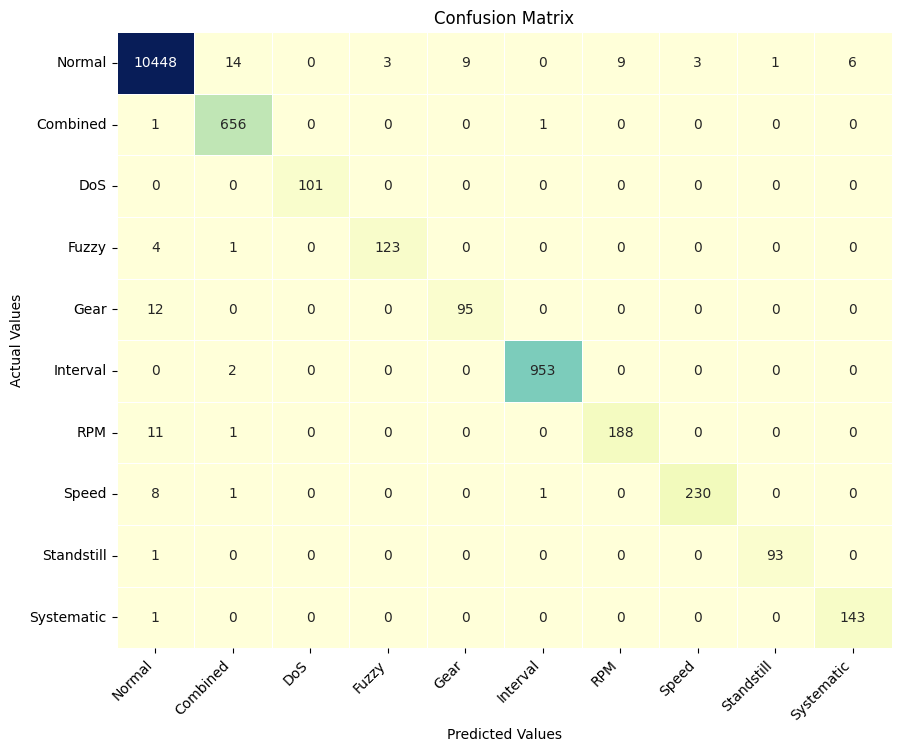

In [26]:
#### visualize confusion matrix
draw_confusion_matrix(conf_matrix, classes, save_file='../images/CCT-RetNet-GPaCo/alpha=1.00/temp=0.07+conf_matrix_batch_size_128_2_layers_2_heads_200_150_epochs_proj_64_220626_epoch_200.png')

#---------------

In [26]:
def change_state_dict(state_dict):
    """
    Because state dict in distributed GPU is different
    """
    new_state_dict = {}
    for k, v in state_dict.items():
        k = k.replace("module.", "")
        new_state_dict[k] = v
    return new_state_dict

In [63]:
import torch.optim as optim
from networks.classifier import LinearClassifier
from networks.resnet_big import SupConResNet

model = SupConResNet('resnet18')
classifier = LinearClassifier(n_classes=5, feat_dim=128)

In [64]:
save_path = '../save/SupCon.resnet18.ce1_lr0.05_0.01_bs512_200epoch_temp0.07_052122_214019_cosine_warm/'
ckpt_epoch = 200
# model_path = f'{save_path}/last.pth'
model_path = f'{save_path}/models/ckpt_epoch_{ckpt_epoch}.pth'
ckpt = torch.load(model_path)
state_dict = ckpt['model']
state_dict = change_state_dict(state_dict)
model.load_state_dict(state_dict=state_dict)

<All keys matched successfully>

In [65]:
class_model_path = f'{save_path}/models/ckpt_class_epoch_{ckpt_epoch}.pth'
# class_model_path = f'{save_path}/last.pth'
ckpt = torch.load(class_model_path)
state_dict = ckpt['model']
classifier.load_state_dict(state_dict=state_dict)

<All keys matched successfully>

In [66]:
import numpy as np
import tqdm
total_pred = np.empty(shape=(0), dtype=int)
total_label = np.empty(shape=(0), dtype=int)
total_embs = np.empty(shape=(0, 128), dtype=float)

model = model.cuda()
classifier = classifier.cuda()
model.eval()
classifier.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(val_loader):
        images = images.cuda(non_blocking=True)
        embs = model.encoder(images)
        outputs = classifier(embs)
        _, pred = outputs.topk(1, 1, True, True)
        pred = pred.t().cpu().numpy().squeeze(0)
        embs = embs.cpu().numpy()
        total_embs = np.concatenate((total_embs, embs), axis=0)
        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)

100%|██████████| 162/162 [00:48<00:00,  3.36it/s]


In [67]:
from utils import cal_metric
cm, results = cal_metric(total_label, total_pred)
for key, values in results.items():
    print(list("{0:0.4f}".format(i) for i in values)) 

['0.0010', '0.0046', '0.0504', '0.0528', '0.0483']
['1.0000', '1.0000', '0.9995', '0.9995', '0.9995']
['0.9997', '1.0000', '1.0000', '1.0000', '1.0000']
['0.9999', '1.0000', '0.9997', '0.9997', '0.9997']


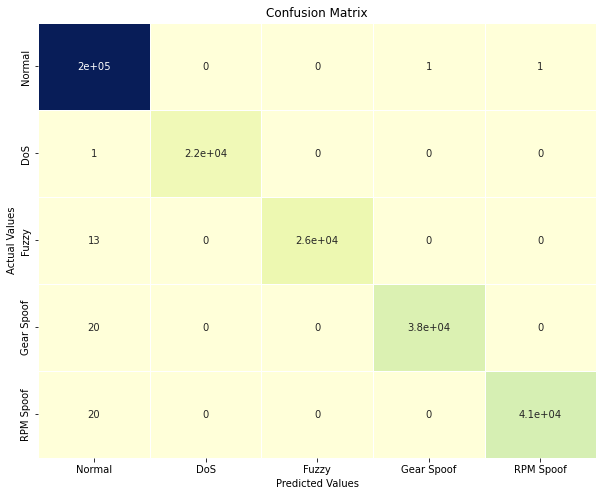

In [68]:
classes = ['Normal', 'DoS', 'Fuzzy', 'Gear Spoof', 'RPM Spoof']
draw_confusion_matrix(cm, classes, save_dir='../figures/confusion_matrix_supcon.png')